---
title: "L4-05 · Frontdoor identification"
short_title: "Frontdoor identification"
subtitle: "When every backdoor path runs through a hidden cause, a measured mediator that carries all of the effect and is shielded from that cause lets us identify the effect in two backdoor steps: treatment to mediator, then mediator to outcome."
description: "State the three frontdoor conditions, derive the frontdoor formula, and compute an intervention effect when treatment and outcome share an unmeasured cause."
tags: [level-4, coursebook]
---

(lesson-l4-05)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 110 minutes  
**Big idea.** When every backdoor path runs through a hidden cause, a measured mediator that carries all of the effect and is shielded from that cause lets us identify the effect in two backdoor steps: treatment to mediator, then mediator to outcome.  
**Before this lesson.** [L4-04](#lesson-l4-04)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- State the three frontdoor conditions and check each one on a graph, including graphs with a direct arrow or a hidden cause of the mediator, where they fail.
- Derive the frontdoor formula for the canonical graph from the truncated factorization with the hidden variable, naming the conditional independence used at each step.
- Compute $P(y \mid do(x))$ from the two identified pieces, $P(m \mid x)$ and the standardized mediator response, and compare it with the naive contrast.
- Verify the formula by simulation and measure how far it moves from the truth when a frontdoor condition is violated.

## Why this matters

Backdoor adjustment ([L4-04](#lesson-l4-04)) needs a measured set that blocks every backdoor path. Often there is none. Suppose a hidden factor $U$ raises both the chance of exposure $X$ and the risk of the outcome $Y$. Every backdoor path runs through $U$, and $U$ is not in the data. It seems that the effect of $X$ on $Y$ cannot be computed from observational data at all.

Pearl showed that it sometimes can [@frontdoor]. His illustration was hypothetical: if smoking affected cancer only through tar deposits in the lungs, and a hidden genotype affected smoking and cancer but not tar, then the effect of smoking would be identified from data on smoking, tar and cancer, even with the genotype unmeasured. The trick is to identify two smaller effects, each by a backdoor argument, and chain them. This lesson proves the formula, computes it, and shows how quickly it breaks when its conditions fail. The smoking story is used only as an illustration of the graph, not as a claim about real biology.

:::{dropdown} Key terms

**Unmeasured confounder**
: A common cause of treatment and outcome that is not recorded, drawn as a dashed node $U$; it opens a backdoor path that no measured set can block.

**Mediator**
: A variable $M$ on a directed path $X \to M \to Y$, through which part or all of the effect of $X$ on $Y$ passes.

**Frontdoor criterion**
: Three graphical conditions on a set $M$: it intercepts every directed path from $X$ to $Y$, there is no open backdoor path from $X$ to $M$, and $X$ blocks every backdoor path from $M$ to $Y$.

**Standardized mediator response**
: $r(m) = \sum_{x'} P(y \mid m, x')P(x')$, the outcome risk at mediator value $m$ averaged over the population distribution of the treatment; it equals $P(y \mid do(m))$ under the frontdoor conditions.

**Averaging index $x'$**
: A dummy treatment value summed over in $r(m)$, distinct from the intervention value $x$.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_05 as _lessonfigs

## When the backdoor is locked

Here is the running model. All variables are binary. The hidden $U$ is fair, $P(U = 1) = 0.5$. Treatment depends on $U$: $P(X = 1 \mid U) = 0.25 + 0.5U$. The mediator depends only on treatment: $P(M = 1 \mid X) = 0.2 + 0.6X$. The outcome depends on the mediator and on $U$: $P(Y = 1 \mid M, U) = 0.6M + 0.4U$. We observe only $X$, $M$ and $Y$.

```{mermaid}
graph LR
  U((U hidden)) -.-> X
  U -.-> Y
  X --> M
  M --> Y
```

*The canonical frontdoor graph. The dashed arrows come from the unmeasured $U$. The only directed path from $X$ to $Y$ passes through the measured mediator $M$.*

:::{prf:definition} Frontdoor criterion
:label: def-l4-05-frontdoor
A set of variables $M$ satisfies the **frontdoor criterion** relative to an ordered pair $(X, Y)$ if

1. $M$ intercepts every directed path from $X$ to $Y$;
2. there is no unblocked backdoor path from $X$ to $M$;
3. every backdoor path from $M$ to $Y$ is blocked by $X$.

Blocking is the d-separation rule of [L4-02](#lesson-l4-02) [@pearlcausality; @frontdoor].
:::

:::{figure} ../../_static/animations/l4_05_frontdoor_graph.mp4
:alt: A graph with X, M, Y in a row and a dashed unmeasured U above with arrows to X and Y. The backdoor path is highlighted, then the three frontdoor conditions are checked one at a time, then a direct X to Y arrow and a U to M arrow are added to show failures.
:width: 100%

The backdoor path $X \leftarrow U \rightarrow Y$ cannot be blocked, but the three frontdoor conditions hold. A direct arrow $X \to Y$ breaks condition 1; an arrow $U \to M$ breaks conditions 2 and 3.
:::

:::{dropdown} What the animation shows
The graph shows $X \to M \to Y$ and a dashed node $U$, labeled unmeasured, with dashed arrows to $X$ and $Y$. The backdoor path $X \leftarrow U \rightarrow Y$ is highlighted in red: it cannot be blocked because $U$ is not observed, so backdoor adjustment is unavailable. Three condition cards then appear. Condition 1: the directed path $X \to M \to Y$ is the only directed path from $X$ to $Y$, and it passes through $M$. Condition 2: the only backdoor path from $X$ to $M$, $X \leftarrow U \rightarrow Y \leftarrow M$, is blocked by the collider $Y$. Condition 3: the backdoor path from $M$ to $Y$, $M \leftarrow X \leftarrow U \rightarrow Y$, is blocked by conditioning on $X$. Then a curved red arrow from $X$ to $Y$ is added, and condition 1 fails. It is removed, and a red arrow from $U$ to $M$ is added, and conditions 2 and 3 fail. The final line says that a measured mediator alone is not enough.
:::

Check the conditions by hand on the canonical graph. The only directed path from $X$ to $Y$ is $X \to M \to Y$, so condition 1 holds. The only path from $X$ to $M$ that starts with an arrow into $X$ is $X \leftarrow U \rightarrow Y \leftarrow M$, and $Y$ is a collider on it, so with nothing conditioned it is blocked: condition 2 holds. The only backdoor path from $M$ to $Y$ is $M \leftarrow X \leftarrow U \rightarrow Y$; $X$ is a noncollider on it, so conditioning on $X$ blocks it: condition 3 holds.

## Deriving the frontdoor formula

:::{prf:lemma} Two independences in the canonical graph
:label: lem-l4-05-indep
In the graph $U \to X \to M \to Y \leftarrow U$, the d-separation rule gives $Y \perp\!\!\!\perp X \mid M, U$ and $U \perp\!\!\!\perp M \mid X$.
:::

:::{prf:proof}
The paths between $Y$ and $X$ are $Y \leftarrow M \leftarrow X$, blocked by the conditioned noncollider $M$, and $Y \leftarrow U \rightarrow X$, blocked by the conditioned noncollider $U$. The paths between $U$ and $M$ are $U \rightarrow X \rightarrow M$, blocked by the conditioned noncollider $X$, and $U \rightarrow Y \leftarrow M$, blocked because the collider $Y$ is not conditioned on and has no descendants. By the Markov property of the DAG ([L4-02](#lesson-l4-02)), d-separation implies conditional independence.
:::

:::{prf:theorem} Frontdoor formula for the canonical graph
:label: thm-l4-05-canonical
In the canonical graph, with $U$ unmeasured, suppose $P(x, m) > 0$ for every pair $(x, m)$. Then [](#eq-l4-05-frontdoor) holds, where $x'$ is a summation index that runs over the values of $X$.
:::

$$
P(y \mid do(x)) = \sum_m P(m \mid x) \sum_{x'} P(y \mid m, x')\, P(x')
$$ (eq-l4-05-frontdoor)

:::{prf:proof}
*Proof for the canonical graph.* Apply the truncated factorization ([L4-04](#lesson-l4-04), equation [](#eq-l4-04-truncated)) to the full graph, $U$ included, and remove the factor of $X$:

$P(u, m, y \mid do(x)) = P(u)\, P(m \mid x)\, P(y \mid m, u)$.

Sum over $u$ and $m$ and collect the terms that depend on $u$:

$P(y \mid do(x)) = \sum_m P(m \mid x) \sum_u P(y \mid m, u)\, P(u)$.

The inner sum involves the hidden $U$. Rewrite it with observed quantities. For each $x'$, condition on $U$:

$P(y \mid m, x') = \sum_u P(y \mid m, u, x')\, P(u \mid m, x') = \sum_u P(y \mid m, u)\, P(u \mid x')$,

using $Y \perp\!\!\!\perp X \mid M, U$ for the first factor and $U \perp\!\!\!\perp M \mid X$ for the second ([](#lem-l4-05-indep)). Multiply by $P(x')$ and sum over $x'$; since $\sum_{x'} P(u \mid x')P(x') = P(u)$,

$\sum_{x'} P(x')\, P(y \mid m, x') = \sum_u P(y \mid m, u)\, P(u)$.

Substituting this into the inner sum gives [](#eq-l4-05-frontdoor). Positivity makes every conditional probability on the right defined.
:::

:::{figure} ../../_static/animations/l4_05_derivation.mp4
:alt: The frontdoor derivation written as a chain of equations whose terms slide into new positions, with the hidden-variable average boxed and then replaced by an average over treatment values.
:width: 100%

The derivation term by term: truncated factorization with $U$, collect the $u$ terms, replace the hidden average by an observed one using two independences, then plug in the numbers.
:::

:::{dropdown} What the animation shows
The first line is $P(y \mid do(x)) = \sum_u \sum_m P(u) P(m \mid x) P(y \mid m, u)$, labeled as the truncated factorization on the full graph. Its terms slide into $\sum_m P(m \mid x) \sum_u P(y \mid m, u) P(u)$. The inner sum is boxed with the warning that $U$ is unmeasured. Below, a second chain shows $\sum_{x'} P(x') P(y \mid m, x') = \sum_{x'} P(x') \sum_u P(y \mid m, u, x') P(u \mid m, x')$, then, using $Y \perp\!\!\!\perp X \mid M, U$ and $U \perp\!\!\!\perp M \mid X$, $\sum_{x'} P(x') \sum_u P(y \mid m, u) P(u \mid x')$, then $\sum_u P(y \mid m, u) P(u)$. The boxed term is replaced, giving the frontdoor formula in which every term is observable. Finally the numbers: $P(Y=1 \mid do(X=1)) = 0.8(0.8) + 0.2(0.2) = 0.68$ and $P(Y=1 \mid do(X=0)) = 0.2(0.8) + 0.8(0.2) = 0.32$.
:::

:::{prf:theorem} Frontdoor adjustment (general graphs)
:label: thm-l4-05-general
If a set $M$ satisfies the frontdoor criterion relative to $(X, Y)$ and $P(x, m) > 0$ for all $x$ and $m$, then the effect of $X$ on $Y$ is identified by [](#eq-l4-05-frontdoor), with $m$ running over the joint values of $M$ [@pearlcausality; @frontdoor].
:::

:::{prf:remark} Why the general proof is two backdoor steps
*Proof sketch.* Condition 2 says the empty set satisfies the backdoor criterion for $(X, M)$, so $P(m \mid do(x)) = P(m \mid x)$. Condition 3 says $\{X\}$ satisfies the backdoor criterion for $(M, Y)$, so $P(y \mid do(m)) = \sum_{x'} P(y \mid m, x')P(x')$: this is the standardized response $r(m)$. Condition 1 lets the two be chained, $P(y \mid do(x)) = \sum_m P(m \mid do(x))\, P(y \mid do(m))$; making that chaining step rigorous in an arbitrary graph uses the do-calculus of [L4-07](#lesson-l4-07) [@pearlcausality]. The proof above with $U$ is a complete proof for the canonical graph only.
:::

## Two identified pieces

Compute the pieces from the observed distribution of the running model. Bayes' rule gives $P(X = 1) = 0.5$, $P(U = 1 \mid X = 1) = 0.75$ and $P(U = 1 \mid X = 0) = 0.25$. Piece 1 is $P(M = 1 \mid X = 1) = 0.8$ and $P(M = 1 \mid X = 0) = 0.2$. The observed outcome risks are $P(Y = 1 \mid M = 1, X = 0) = 0.7$ and $P(Y = 1 \mid M = 1, X = 1) = 0.9$, and $0.1$ and $0.3$ when $M = 0$. Piece 2 averages over $x'$ with $P(x') = 0.5$: $r(1) = 0.5(0.7) + 0.5(0.9) = 0.8$ and $r(0) = 0.5(0.1) + 0.5(0.3) = 0.2$.

$$
P(Y = 1 \mid do(X = 1)) = 0.8(0.8) + 0.2(0.2) = 0.68, \qquad P(Y = 1 \mid do(X = 0)) = 0.2(0.8) + 0.8(0.2) = 0.32
$$ (eq-l4-05-numbers)

:::{figure} ../../_static/animations/l4_05_assembly.mp4
:alt: Two bar charts: P(M = 1 | x) with bars 0.2 and 0.8, and the standardized response r(m) with bars 0.2 and 0.8. The two formula pieces then fly into the full frontdoor formula, and the results 0.68, 0.32 and effect 0.36 appear.
:width: 100%

Piece 1 is the effect of $X$ on $M$; piece 2 is the effect of $M$ on $Y$, adjusted for $X$. Assembled, they give the effect $0.36$, while the naive contrast is $0.56$.
:::

:::{dropdown} What the animation shows
On the left, piece 1, $P(m \mid x)$, is drawn as bars 0.2 at $x = 0$ and 0.8 at $x = 1$; it needs no adjustment because there is no open backdoor path from $X$ to $M$. On the right, piece 2, $\sum_{x'} P(y \mid m, x') P(x')$, is computed as $r(1) = 0.5(0.7) + 0.5(0.9) = 0.8$ and $r(0) = 0.5(0.1) + 0.5(0.3) = 0.2$ and drawn as bars. The two formula pieces then move into the full formula $P(y \mid do(x)) = \sum_m P(m \mid x) \sum_{x'} P(y \mid m, x') P(x')$. The results appear: $do(X = 1)$ gives 0.68, $do(X = 0)$ gives 0.32, and the effect is 0.36. A last line notes that the naive contrast $0.78 - 0.22 = 0.56$ is biased by $U$.
:::

The effect is $0.68 - 0.32 = 0.36$. Because the model is explicit, we can check it against the truth computed with $U$: $P(Y = 1 \mid do(x)) = \sum_m P(m \mid x)\,(0.6m + 0.4 \cdot 0.5)$, which is $0.68$ and $0.32$. The naive contrast is $P(Y = 1 \mid X = 1) - P(Y = 1 \mid X = 0) = 0.78 - 0.22 = 0.56$: people who take the treatment also tend to have $U = 1$. With a binary mediator the effect factorizes, $[P(M = 1 \mid 1) - P(M = 1 \mid 0)]\,[r(1) - r(0)] = 0.6 \times 0.6 = 0.36$: the effect of $X$ on $M$ times the effect of $M$ on $Y$.

:::{important} Why piece 2 averages over $x'$
Conditioning on $X$ blocks the backdoor path $M \leftarrow X \leftarrow U \rightarrow Y$, so within each value $x'$ the association of $M$ with $Y$ is causal. Averaging over the population distribution $P(x')$ is backdoor standardization with $\{X\}$ as the adjustment set. Using $P(y \mid m)$ instead would leave that path open.
:::


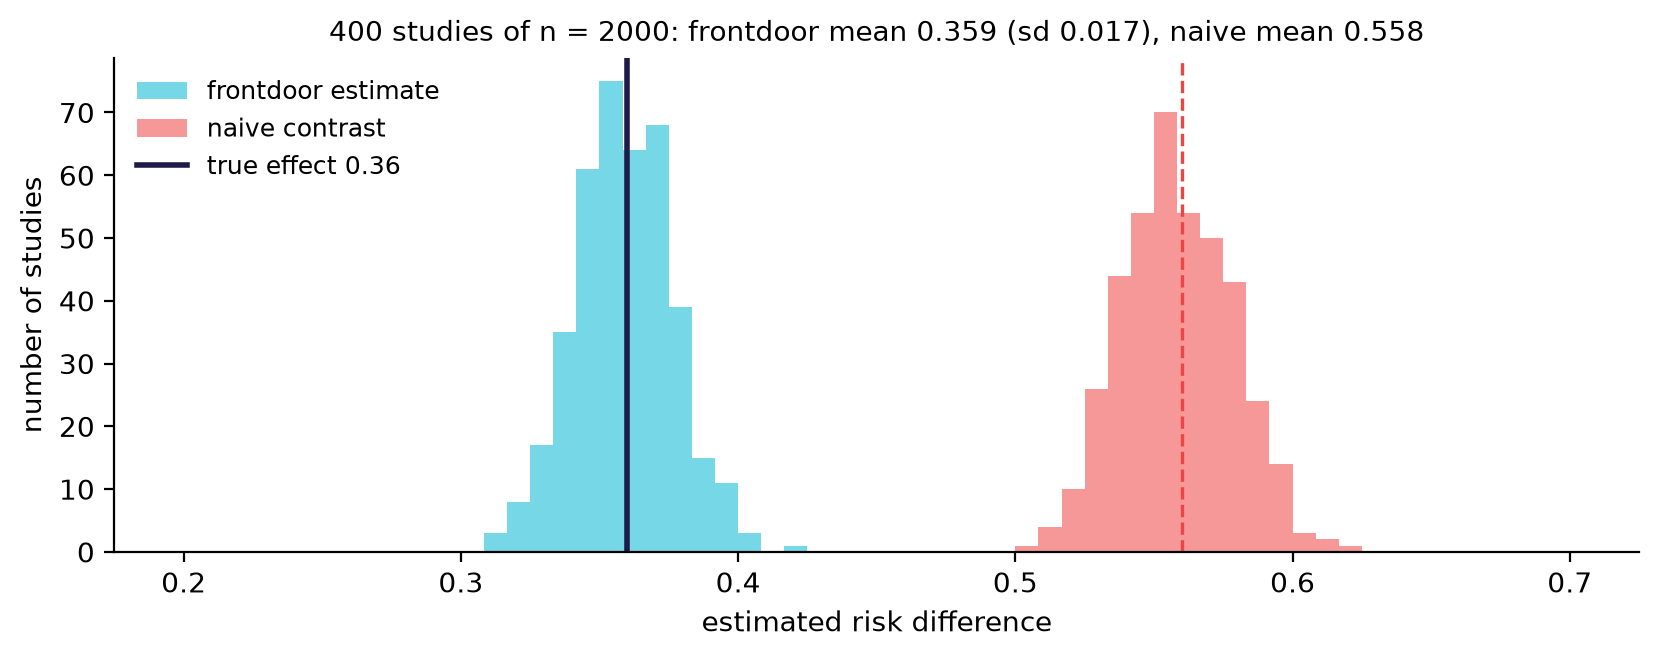

In [2]:
_show_mpl(_lessonfigs.sampling_distributions())

*400 simulated studies of 2000 units each from the running model. The frontdoor estimate centers on the true effect 0.36; the naive contrast centers on 0.56. Finite samples add spread, not bias.*

## When the conditions fail

The formula is exact only on a graph that satisfies the criterion. Two small edits break it. A **direct arrow** $X \to Y$, modeled as $P(Y = 1 \mid M, U, X) = (1 - s)(0.6M + 0.4U) + sX$, violates condition 1: part of the effect bypasses $M$, and the formula misses it. A **hidden arrow** $U \to M$, modeled as $P(M = 1 \mid X, U) = (1 - s)(0.2 + 0.6X) + sU$, violates conditions 2 and 3: piece 1 is now confounded, and $X$ no longer blocks every path from $M$ to $Y$.

```{mermaid}
graph LR
  U((U hidden)) -.-> X
  U -.-> Y
  U -.->|violation B| M
  X --> M
  M --> Y
  X -->|violation A| Y
```

*The two violations explored below: a direct arrow $X \to Y$ (A) and an arrow from the hidden $U$ into the mediator (B). Either one makes the frontdoor formula biased.*


In [3]:
_show(_lessonfigs.frontdoor_violations())

**Explore.** Increase the violation strength $s$. With $s = 0$ the frontdoor formula equals the truth; as $s$ grows, it drifts away in both violated models.

:::{dropdown} What the figure shows
The first panel shows three bars for each violated model: the true risk difference, the value of the frontdoor formula computed from the exact observed distribution, and the naive contrast. The second panel plots the frontdoor formula minus the truth against $s$ from 0 to 0.5 for both models, with markers at the chosen $s$. At $s = 0$ both biases are 0. With the direct arrow at $s = 0.5$ the truth is 0.68 and the formula gives 0.18; with the arrow $U \to M$ at $s = 0.5$ the truth is 0.18 and the formula gives about 0.45.
:::

:::{warning} The conditions cannot be checked from the data
In the canonical graph every pair of observed variables is connected by an arrow or by a path that no observed set blocks, so the graph implies no conditional independence among $X$, $M$ and $Y$ that the data could test. Whether the mediator carries all of the effect and is unconfounded with the outcome is a substantive assumption. The frontdoor criterion is sufficient for identification, not necessary; other graphs are identified by other arguments ([L4-07](#lesson-l4-07)).
:::

## Compute it

Check the two independences with `networkx`, compute the frontdoor formula exactly from the model's observed distribution, then estimate it from 120,000 simulated rows of $(X, M, Y)$ only. The 'backdoor on $U$' line is an oracle that uses the hidden variable, for comparison.


In [4]:
import itertools
import numpy as np
import networkx as nx

# 1. the two independences used in the proof, read off the graph by d-separation
G = nx.DiGraph([("U", "X"), ("U", "Y"), ("X", "M"), ("M", "Y")])
print("Y indep. X given {M, U}:", nx.is_d_separator(G, {"Y"}, {"X"}, {"M", "U"}))
print("U indep. M given X:     ", nx.is_d_separator(G, {"U"}, {"M"}, {"X"}))
print("X indep. Y given M:     ", nx.is_d_separator(G, {"X"}, {"Y"}, {"M"}), "(so adjusting for M is not enough)")

# 2. exact values from the model: U fair, P(X=1|U)=0.25+0.5U, P(M=1|X)=0.2+0.6X, P(Y=1|M,U)=0.6M+0.4U
def p(v, prob):
    return prob if v else 1 - prob
J = {(u, x, m, y): p(u, 0.5) * p(x, 0.25 + 0.5 * u) * p(m, 0.2 + 0.6 * x) * p(y, 0.6 * m + 0.4 * u)
     for u, x, m, y in itertools.product((0, 1), repeat=4)}
def P(**f):
    return sum(v for k, v in J.items() if all(k["uxmy".index(n)] == w for n, w in f.items()))
px = {x: P(x=x) for x in (0, 1)}
r = {m: sum(P(m=m, x=x, y=1) / P(m=m, x=x) * px[x] for x in (0, 1)) for m in (0, 1)}
fd = {x: sum(P(x=x, m=m) / px[x] * r[m] for m in (0, 1)) for x in (0, 1)}
true = {x: sum(p(u, 0.5) * p(m, 0.2 + 0.6 * x) * (0.6 * m + 0.4 * u) for u in (0, 1) for m in (0, 1)) for x in (0, 1)}
print("exact frontdoor:", {k: round(v, 4) for k, v in fd.items()}, " exact truth:", {k: round(v, 4) for k, v in true.items()})

# 3. simulation: the estimate uses only (X, M, Y)
rng = np.random.default_rng(7)
def simulate(n, do_x=None):
    u = rng.random(n) < 0.5
    x = (rng.random(n) < 0.25 + 0.5 * u) if do_x is None else np.full(n, bool(do_x))
    m = rng.random(n) < 0.2 + 0.6 * x
    y = rng.random(n) < 0.6 * m + 0.4 * u
    return u, x, m, y

n = 120_000
u, x, m, y = simulate(n)
px1 = x.mean()
pm1 = {1: m[x].mean(), 0: m[~x].mean()}
def resp(mv):
    sel = m == mv
    return y[sel & x].mean() * px1 + y[sel & ~x].mean() * (1 - px1)
est = {xv: pm1[xv] * resp(1) + (1 - pm1[xv]) * resp(0) for xv in (0, 1)}
naive = y[x].mean() - y[~x].mean()
oracle = sum(np.mean(u == uv) * (y[x & (u == uv)].mean() - y[~x & (u == uv)].mean()) for uv in (False, True))
truth = simulate(n, 1)[3].mean() - simulate(n, 0)[3].mean()
print(f"naive contrast       {naive:.3f}   (exact 0.56)")
print(f"frontdoor estimate   {est[1] - est[0]:.3f}")
print(f"backdoor on U        {oracle:.3f}   (only possible if U were measured)")
print(f"simulated do(X)      {truth:.3f}   (exact 0.68 - 0.32 = 0.36)")

Y indep. X given {M, U}: True
U indep. M given X:      True
X indep. Y given M:      False (so adjusting for M is not enough)
exact frontdoor: {0: 0.32, 1: 0.68}  exact truth: {0: 0.32, 1: 0.68}
naive contrast       0.558   (exact 0.56)
frontdoor estimate   0.358
backdoor on U        0.358   (only possible if U were measured)
simulated do(X)      0.361   (exact 0.68 - 0.32 = 0.36)


:::{prf:remark} Estimation
The plug-in estimator replaces each probability in [](#eq-l4-05-frontdoor) by a sample frequency, as in the code. With many mediator values or continuous variables, the two pieces are fitted with models, and their errors combine; the delta method or the bootstrap gives uncertainty intervals ([L3-10](#lesson-l3-10)). Identification guarantees only that the target is a function of the observed distribution; it says nothing about how many samples are needed [@bradyneal].
:::

## Worked example

:::{admonition} A frontdoor calculation from an observed table
:class: tip

Assume a valid frontdoor graph. The observed distribution has $P(X = 1) = 0.4$, $P(M = 1 \mid X = 1) = 0.7$, $P(M = 1 \mid X = 0) = 0.1$, and outcome risks $P(Y = 1 \mid M = m, X = x)$ of $0.5$ for $(1, 1)$, $0.3$ for $(1, 0)$, $0.4$ for $(0, 1)$ and $0.2$ for $(0, 0)$. Find $P(Y = 1 \mid do(X = x))$ for both $x$, the effect, and the naive contrast.

1. Standardized responses with $P(x') = (0.6, 0.4)$ for $x' = 0, 1$: $r(1) = 0.4(0.5) + 0.6(0.3) = 0.38$ and $r(0) = 0.4(0.4) + 0.6(0.2) = 0.28$.
2. Combine with piece 1: $P(Y = 1 \mid do(X = 1)) = 0.7(0.38) + 0.3(0.28) = 0.35$ and $P(Y = 1 \mid do(X = 0)) = 0.1(0.38) + 0.9(0.28) = 0.29$.
3. Check with the binary shortcut: $[0.7 - 0.1]\,[0.38 - 0.28] = 0.6 \times 0.10 = 0.06$.
4. Naive risks: $P(Y = 1 \mid X = 1) = 0.7(0.5) + 0.3(0.4) = 0.47$ and $P(Y = 1 \mid X = 0) = 0.1(0.3) + 0.9(0.2) = 0.21$, a naive contrast of $0.26$.

**Result.** The frontdoor effect is $0.35 - 0.29 = 0.06$, far smaller than the naive $0.26$; most of the observed association comes from the hidden common cause.
:::

## Exercises

**1. (Core)** Assume a valid frontdoor graph. The standardized responses for $M = 1$ and $M = 0$ are $0.6$ and $0.2$. The probabilities of $M = 1$ at $X = 1$ and $X = 0$ are $0.75$ and $0.25$. Find both intervention risks and their difference.

:::{dropdown} Solution
At $X = 1$: $0.75(0.6) + 0.25(0.2) = 0.50$. At $X = 0$: $0.25(0.6) + 0.75(0.2) = 0.30$. The risk difference is $0.20$, which also equals $(0.75 - 0.25)(0.6 - 0.2)$.
:::

**2. (Core)** For each graph, say whether $\{M\}$ satisfies the frontdoor criterion relative to $(X, Y)$, and name the failing condition if not. (a) $U \to X$, $U \to Y$, $X \to M \to Y$. (b) Graph (a) plus $X \to Y$. (c) Graph (a) plus $U \to M$. (d) Graph (a) plus a second hidden $V$ with $V \to M$ and $V \to Y$.

:::{dropdown} Solution
(a) Yes, all three conditions hold. (b) No: the directed path $X \to Y$ avoids $M$, so condition 1 fails. (c) No: $X \leftarrow U \rightarrow M$ is an open backdoor path from $X$ to $M$ (condition 2), and $M \leftarrow U \rightarrow Y$ is a backdoor path from $M$ to $Y$ that $X$ does not block (condition 3). (d) No: $M \leftarrow V \rightarrow Y$ is a backdoor path from $M$ to $Y$ that does not pass through $X$, so condition 3 fails; condition 2 still holds because $X \leftarrow U \rightarrow Y \leftarrow V \rightarrow M$ is blocked at the collider $Y$.
:::

**3. (Stretch)** Show that for a binary mediator, $P(y \mid do(X = 1)) - P(y \mid do(X = 0)) = [P(M = 1 \mid X = 1) - P(M = 1 \mid X = 0)]\,[r(1) - r(0)]$, and interpret each factor.

:::{dropdown} Solution
From [](#eq-l4-05-frontdoor), $P(y \mid do(x)) = r(0) + P(M = 1 \mid x)\,[r(1) - r(0)]$, since $P(M = 0 \mid x) = 1 - P(M = 1 \mid x)$. Subtracting the $x = 0$ value from the $x = 1$ value cancels $r(0)$ and leaves the product. The first factor is the causal effect of $X$ on $M$ (identified because condition 2 holds); the second is the causal effect of $M$ on $Y$, $P(y \mid do(M = 1)) - P(y \mid do(M = 0))$ (identified by adjusting for $X$).
:::

**4. (Stretch)** In the running model, someone computes piece 2 as $P(Y = 1 \mid M = m)$ instead of $r(m)$. Find $P(Y = 1 \mid M = 1)$, $P(Y = 1 \mid M = 0)$ and the resulting 'effect'. Why is it wrong?

:::{dropdown} Solution
$P(M = 1) = 0.5(0.8) + 0.5(0.2) = 0.5$, so $P(X = 1 \mid M = 1) = 0.4/0.5 = 0.8$ and $P(X = 1 \mid M = 0) = 0.1/0.5 = 0.2$. Then $P(Y = 1 \mid M = 1) = 0.8(0.9) + 0.2(0.7) = 0.86$ and $P(Y = 1 \mid M = 0) = 0.2(0.3) + 0.8(0.1) = 0.14$. The 'effect' is $0.6 \times (0.86 - 0.14) = 0.432$ instead of $0.36$. Without conditioning on $X$, the path $M \leftarrow X \leftarrow U \rightarrow Y$ is open, so $P(y \mid m)$ mixes the effect of $M$ with confounding by $U$.
:::

**5. (Challenge)** Show directly that in the canonical model the frontdoor formula agrees with the backdoor formula you could use if $U$ were measured, $\sum_u P(y \mid x, u) P(u)$.

:::{dropdown} Solution
By [](#lem-l4-05-indep) and the chain rule, $P(y \mid x, u) = \sum_m P(m \mid x, u)\, P(y \mid m, x, u) = \sum_m P(m \mid x)\, P(y \mid m, u)$, because $M$ depends on $(X, U)$ only through $X$ ($U \perp\!\!\!\perp M \mid X$) and $Y \perp\!\!\!\perp X \mid M, U$. Hence $\sum_u P(u) P(y \mid x, u) = \sum_m P(m \mid x) \sum_u P(y \mid m, u) P(u)$, which is the second line of the proof of [](#thm-l4-05-canonical), and that equals [](#eq-l4-05-frontdoor). Both formulas compute the same $P(y \mid do(x))$; only the frontdoor one avoids $U$.
:::

**6. (Challenge)** A treatment acts through two measured mediators in parallel, $X \to M_1 \to Y$ and $X \to M_2 \to Y$, and a hidden $U$ causes $X$ and $Y$. Show that $\{M_1, M_2\}$ satisfies the frontdoor criterion and write the identifying formula.

:::{dropdown} Solution
Condition 1: the directed paths from $X$ to $Y$ are $X \to M_1 \to Y$ and $X \to M_2 \to Y$, and both pass through the set. Condition 2: every backdoor path from $X$ to $M_1$ or $M_2$ starts $X \leftarrow U \rightarrow Y$ and then enters a mediator against an arrow ($Y \leftarrow M_j$), so $Y$ is a collider and the path is blocked. Condition 3: the backdoor paths from the mediators to $Y$ are $M_j \leftarrow X \leftarrow U \rightarrow Y$ and $M_1 \leftarrow X \rightarrow M_2 \rightarrow Y$ (and the mirror image), and each has $X$ as a noncollider, so conditioning on $X$ blocks them. The formula is $P(y \mid do(x)) = \sum_{m_1, m_2} P(m_1, m_2 \mid x) \sum_{x'} P(y \mid m_1, m_2, x')\, P(x')$, given positivity.
:::

## Check your understanding

**1. Which condition is part of the ordinary frontdoor criterion?**

- **A.** The mediator must be a parent of $X$
- **B.** The mediator may skip some directed paths from $X$ to $Y$
- **C.** The mediator must intercept every directed path from $X$ to $Y$
- **D.** All hidden causes must be measured

:::{dropdown} Show the answer
**C. The mediator must intercept every directed path from $X$ to $Y$**

Condition 1 requires every directed path from treatment to outcome to pass through the mediator. Hidden treatment-outcome confounding is allowed; that is the point of the criterion.
:::

**2. In a valid frontdoor graph, $r(1) = 0.8$, $r(0) = 0.2$ and $P(M = 1 \mid X = x) = 0.5$. What is $P(Y = 1 \mid do(X = x))$?**

- **A.** 0.5
- **B.** 0.4
- **C.** 0.68
- **D.** 0.8

:::{dropdown} Show the answer
**A. 0.5**

$0.5(0.8) + 0.5(0.2) = 0.5$. The frontdoor formula is a weighted average of the standardized responses with weights $P(m \mid x)$.
:::

**3. Why does piece 2 average $P(y \mid m, x')$ over $x'$ with weights $P(x')$ instead of using $P(y \mid m)$?**

- **A.** To remove the effect of $M$ on $Y$
- **B.** Because $X$ is a collider between $M$ and $Y$
- **C.** Because $P(y \mid m)$ is not defined
- **D.** Conditioning on $X$ blocks the backdoor path $M \leftarrow X \leftarrow U \rightarrow Y$

:::{dropdown} Show the answer
**D. Conditioning on $X$ blocks the backdoor path $M \leftarrow X \leftarrow U \rightarrow Y$**

This is backdoor adjustment for the effect of $M$ on $Y$, with $\{X\}$ as the adjustment set. Without $X$ the path through the hidden $U$ stays open.
:::

**4. In backdoor adjustment, why may an adjustment set not contain a descendant of the treatment?** *(Review of [L4-04](#lesson-l4-04))*

- **A.** Descendants always have probability zero
- **B.** Conditioning on it can block part of the effect or open new paths
- **C.** It makes the formula use $P(z \mid x)$ instead of $P(z)$
- **D.** Descendants are never measured

:::{dropdown} Show the answer
**B. Conditioning on it can block part of the effect or open new paths**

A descendant such as a mediator carries part of the effect, so conditioning on it removes that part; a descendant can also be a collider. Condition (i) of the backdoor criterion excludes descendants for this reason.
:::

## Common misconceptions

- **"Any measured mediator lets you identify the effect by the frontdoor formula."** All three conditions are needed. A direct arrow $X \to Y$ or a hidden cause of both $M$ and $Y$ makes the formula biased, as the interactive shows.
- **"The frontdoor formula works by estimating the hidden $U$."** Nothing about $U$ is estimated. The proof shows that the one place $U$ enters, $\sum_u P(y \mid m, u)P(u)$, equals an average over $x'$ of observed quantities.
- **"Frontdoor adjustment means adjusting for the mediator."** Adjusting for $M$ in the usual way would block the effect. The frontdoor formula instead uses $M$ as a stepping stone: the effect of $X$ on $M$, chained with the effect of $M$ on $Y$.
- **"If the frontdoor estimate and the naive contrast differ, the data have proved confounding."** The difference is evidence only under the assumed graph. The frontdoor conditions imply no testable independence among $X$, $M$ and $Y$, so the data cannot confirm the graph.

:::{caution} Scope and limits
The frontdoor formula identifies the effect only if the causal graph is right, in particular if the mediator carries all of the effect and shares no hidden cause with the outcome. These assumptions cannot be tested from data on $X$, $M$ and $Y$ alone. Positivity $P(x, m) > 0$ is required. The criterion is sufficient, not necessary. The smoking and tar story is a hypothetical illustration of the graph, not a claim about real smoking data, and the numbers come from a made-up model. Simulations confirm the algebra; they are not evidence about the world.
:::

:::{seealso} Where this leads
[L4-07](#lesson-l4-07) shows that backdoor and frontdoor adjustment are both special cases of the do-calculus, and that some graphs with hidden variables are not identified at all. Counterfactual questions in [L4-09](#lesson-l4-09) need more than the interventional distribution computed here.
:::

:::{dropdown} For instructors

**Why this lesson.** The frontdoor criterion is the clearest example that identification is a property of the graph and the observed distribution together, not of which variables happen to be confounded. Its proof is short enough to do completely for the canonical graph and shows the logic of the do-calculus without the full calculus [@frontdoor; @pearlcausality].

**Teaching notes.**

- Start by asking students to try backdoor adjustment on the canonical graph and to explain why every candidate set fails. The puzzle motivates the rest.
- Write the derivation on the board in the same order as the animation, and ask students to name the independence used at each step before revealing it.
- Stress the averaging index: $x$ is the intervention value and $x'$ is summed over. Many errors come from merging them.
- Use the interactive to show that a small direct effect produces a large bias; then discuss how rarely the conditions are believable in real applications [@bradyneal].

**Assessment.** The second core exercise tests the conditions on modified graphs; the stretch exercises test the formula's structure; the first challenge exercise tests whether students can connect the frontdoor and backdoor formulas algebraically [@pearl].

**Going further.** Read Pearl's original presentation of the frontdoor graph and compare the do-calculus derivation there with the proof given here [@frontdoor]. Then show that the conditional frontdoor formula, with measured covariates $C$ that block some backdoor paths, is obtained by applying the same argument within each stratum of $C$ [@pearlcausality].

:::

## References

This lesson draws on [@frontdoor; @pearlcausality; @pearl; @bradyneal; @peters].

**Further reading.**

- [@frontdoor]: The original paper, which introduces the frontdoor criterion with the hypothetical smoking, tar and cancer illustration.
- [@bradyneal]: Chapter 6 presents frontdoor adjustment as a sequence of backdoor steps, with figures.
- [@pearlcausality]: Section 3.3.2 states the frontdoor theorem and Section 3.4 derives it with the do-calculus.

**Next:** [L4-06 · Potential outcomes and randomization](#lesson-l4-06)
